# ScaleFM Demo

A scaling analysis answers: *if I train with 20x more compute, what loss will I get,
and which model size, data and hyperparameters should I use?* It does this by
training many smaller models, fitting a scaling law to them, and then extrapolating
to the target cost.

Where this notebook gets to, extrapolating 20x beyond the largest run:

<table>
  <tr>
    <td align="center"><img src="static/chinchilla_loss_over_cost.png" width="360"><br><b>Loss</b>: a power law through the compute-loss frontier</td>
    <td align="center"><img src="static/total_cells_over_cost.png" width="360"><br><b>A hyperparameter</b>: the data, <code>total_cells</code>, of the frontier runs + Extrapolated point</td>
  </tr>
</table>

ScaleFM automates that via this five components:

1. ** Search space** `scalefm.PipelineSpace` declares the hyperparameters of a run as
   `scalefm.Integer` or `scalefm.Float`, on a linear or log scale. Each one is either a
   compute-scaling parameter (`is_compute_scaling=True`), such as the model size or the
   amount of data, or an ordinary hyperparameter, such as the learning rate. ScAn uses
   this split natively.
2. **Acquisition.** Deciding which small runs to train within a compute budget:
   random search (the default), Chinchilla's approach 1, CARBS, or **ScAn**, Bayesian
   optimization that picks the runs that reveal most about the best loss at the target
   compute.
3. **Prediction.** `scalefm.predict` fits the runs with a power law, Chinchilla's
   $L(N, D)$ or a Gaussian process, and returns the loss, the compute-optimal model
   size and data, and a full config at any target compute.
4. **Running at scale.** Many workers, processes, Slurm jobs or machines, share one
   FLOP budget through the filesystem, configs can be handed off to jobs that report
   back later, and a single run can train on many GPUs with PyTorch DDP.
5. **Visualization.** `scalefm.predict` writes the scaling fits of the loss and of
   every downstream metric, the predictions at the target compute and how they
   converged as runs finished; `acquire` adds live plots.

This notebook analyzes scaling behaviour of [TabPFN](https://github.com/PriorLabs/TabPFN), a transformer
for tabular data, on a surrogate benchmark built from thousands of real training
runs on NanoTabPFN.

## Installation
Requires Python 3.11+. In Colab, run the cell below; locally, see the
[README](README.md).

In [ ]:
!rm -rf /content/scalefm_repo
!git clone --depth 1 https://github.com/automl/scalefm.git /content/scalefm_repo
%cd /content/scalefm_repo/tutorials
!uv pip install --system torch==2.9.1 torchvision==0.24.1 --index-url https://download.pytorch.org/whl/cpu
!uv pip install --system -e "/content/scalefm_repo"
# Surrogate benchmark of TabPFN, it makes every run take a fraction of a second.
# Its own dependencies include all of autogluon, only the parts it imports are installed
!uv pip install --system --no-deps scan-bench
!uv pip install --system autogluon.tabular tabpfn xgboost lightgbm seaborn scikit-learn tqdm
# The editable install is only seen after a kernel restart, so it is put on the path
import sys; sys.path[:0] = ["/content/scalefm_repo", "/content/scalefm_repo/tutorials"]

In [1]:
import logging
import os

# The surrogates run in forked worker processes later on, which needs a single
# OpenMP thread (set before they load)
os.environ["OMP_NUM_THREADS"] = "1"
import multiprocessing as mp
import shutil
import subprocess
import sys
import time
import warnings
from pathlib import Path

from IPython.display import Image, display
from scan_bench import TabPFNTarget

import scalefm
import tabpfn_scan_bench as tabpfn

logging.basicConfig(level=logging.WARNING)
logging.getLogger("scalefm").setLevel(logging.INFO)
warnings.filterwarnings("ignore")


def show(*images, width=480):
    """Show PNG files, e.g. the plots of a run's `summary/`."""
    for image in images:
        display(Image(filename=image, width=width))

/home/alipourn/extrapolaw/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## The evalaution pipeline

`evaluate_pipeline` is the function `scalefm.acquire` calls with every config. It
trains a model and returns what the scaling analysis needs: the loss to minimize, the
training cost, the model size and data, and optionally downstream performances and
the inference cost.

Here, the surrogate benchmark of `scan_bench` stands in for the training: it predicts
what a TabPFN training run would reach, its validation loss and its negative
log-likelihood on real tabular datasets, a downstream metric.

In [2]:
loss_benchmark = tabpfn.get_benchmark(TabPFNTarget.VAL_LOSS)
nll_benchmark = tabpfn.get_benchmark(TabPFNTarget.NLL)


def evaluate_pipeline(**config) -> dict:
    """Train TabPFN with `config`, here: ask the surrogates what it would reach."""
    run = tabpfn.build_config(**config)
    flops_per_cell = tabpfn.flops_estimator(**{**config, "total_cells": 1})
    return {
        "objective_to_minimize": loss_benchmark.query(run)["predictions"]["mean"],
        "cost": flops_per_cell * run.total_cells,  # Training FLOPs
        "inference_cost": flops_per_cell / 3,  # FLOPs of a forward pass over one cell
        "n_params": tabpfn.parameters_estimator(**config),
        "n_data": run.total_cells,
        "downstream_performances": {
            "real_nll": nll_benchmark.query(run)["predictions"]["mean"]
        },
    }

In [3]:
config = dict(total_cells=2**25, effective_batch_size=64, lr=1e-3, embedding_size=16, num_layers=4)
evaluate_pipeline(**config)

{'objective_to_minimize': 1.094,
 'cost': 5459968705691.68,
 'inference_cost': 54239.91586458365,
 'n_params': 19402,
 'n_data': 33554432,
 'downstream_performances': {'real_nll': 1.047}}

The benchmark also tells the model size and the training cost of a config without
running it. `acquire` uses the cost estimator to keep every run within
`max_cost_per_config`, and `predict` uses both to turn a predicted model size into a
config.

In [4]:
print(f"{tabpfn.parameters_estimator(**config):.3e} parameters")
print(f"{tabpfn.flops_estimator(**config):.3e} FLOPs")

1.940e+04 parameters
5.460e+12 FLOPs


## The search space

The search space is the most important design decision in a study. It defines every
parameter of a run: its type, its scale (log, linear, ...), its range and its
constraints. If it is badly defined, no optimizer can make up for it. Mark the
parameters that drive compute cost with `is_compute_scaling=True`: the scaling
optimizers lay out their runs along these axes.

The model size is determined by `embedding_size` and `num_layers`, the amount of data by
`total_cells`.

In [5]:
class TabPFNSpace(scalefm.PipelineSpace):
    # Compute-scaling parameters
    total_cells = scalefm.Integer(2**20, 2**35, log=True, log_base=2, is_compute_scaling=True)
    embedding_size = scalefm.Integer(4, 256, log=True, log_base=2, is_compute_scaling=True)
    num_layers = scalefm.Integer(2, 32, log=True, log_base=2, is_compute_scaling=True)
    # The other hyperparameters
    effective_batch_size = scalefm.Integer(16, 256, log=True, log_base=2)
    lr = scalefm.Float(1e-4, 5e-2, log=True)

Every acquisition gets the same FLOP budget, at most a tenth of it per run, and we
predict at two targets, about 3.6x and 20x the cost of the largest run.

In [6]:
RESULTS = Path("results/scaling_tutorial")

MAX_COST_PER_RUN = 2.8e14
BUDGET = MAX_COST_PER_RUN * 10
TARGETS = [1e15, 5.6e15]  # About 3.6x and 20x the cost of the largest run

## Three extrapolations: loss, model size and full config

![Data acquisition, then extrapolation to the loss, model size and full config at the target FLOPs](static/scaling_pipeline.png)

A study has two steps. The **acquisition** trains the small runs within the budget.
The **extrapolation**, `scalefm.predict`, fits a predictor to them and predicts at
the target compute up to three things, each harder than the last:

* the best loss $L^*$, in the field `loss` of each `Prediction`,
* the compute-optimal model size $N^*$ and data $D^*$, in `n_params` and `n_data`,
* the full config $\lambda^*$ to train, with every hyperparameter, in `config`.

Not every predictor gives all three:

| predictor | fits | $L^*$ | $N^*$, $D^*$ | $\lambda^*$ | Comment |
|---|---|---|---|---|---|
| `chinchilla3` | Chinchilla's law $L(N, D)$ | yes | yes | no | -|
| `power_law` | straight lines in log-log through the frontier runs | yes | yes | yes | ignores joint dependency of HPs |
| `gp_posterior` | a Gaussian process over the full config | yes | yes | yes | - |

With `predictor="auto"`, the default, `predict` uses the predictor of the
optimizer that acquired the runs: `chinchilla3` for Chinchilla, `power_law` for
random search, `gp_posterior` for ScAn.

## 1. Chinchilla approach 1

Chinchilla's approach 1 trains a ladder of model sizes, each on a few multiples of
its parameter count in cells (`data_multipliers`), and grows the models until the
budget is spent. From these runs it reads off the lowest loss at each compute, the
compute-optimal frontier. Like the Chinchilla paper it keeps a fixed training recipe,
so it runs on a version of the space with constant hyperparameters:

In [7]:
class TabPFNChinchillaSpace(scalefm.PipelineSpace):
    # Compute-scaling parameters
    total_cells = scalefm.Integer(2**20, 2**35, log=True, log_base=2, is_compute_scaling=True)
    embedding_size = scalefm.Integer(4, 256, log=True, log_base=2, is_compute_scaling=True)
    # The other hyperparameters
    num_layers = 2 # scalefm.Integer(2, 32, log=True, log_base=2, is_compute_scaling=True)
    effective_batch_size = 64 # effective_batch_size = scalefm.Integer(16, 256, log=True, log_base=2)
    lr = 1e-3 # lr = scalefm.Float(1e-4, 5e-2, log=True)


CHINCHILLA1 = RESULTS / "chinchilla1"

tabpfn.set_seed(0)
scalefm.acquire(
    evaluate_pipeline=evaluate_pipeline,
    pipeline_space=TabPFNChinchillaSpace(),
    root_directory=CHINCHILLA1,
    optimizer=(
        "chinchilla",
        {
            "strategy": "approach1",
            "data_parameter_name": "total_cells",
            "params_estimator": tabpfn.parameters_estimator,
            "data_multipliers": [300, 1e3, 3e3, 1e4],
        },
    ),
    cost_estimator=tabpfn.flops_estimator,
    total_cost_to_spend=BUDGET,
    overwrite_root_directory=True,
)

INFO:scalefm.api:Starting scalefm.acquire using root directory results/scaling_tutorial/chinchilla1
INFO:scalefm.api:SearchSpace(elements={'effective_batch_size': HPOConstant(value=64), 'embedding_size': HPOInteger(lower=4, upper=256, center=32, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'lr': HPOConstant(value=0.001), 'num_layers': HPOConstant(value=2), 'total_cells': HPOInteger(lower=1048576, upper=34359738368, center=268435456, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True)}, categoricals={}, numerical={'embedding_size': HPOInteger(lower=4, upper=256, center=32, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'total_cells': HPOInteger(lower=1048576, upper=34359738368, center=268435456, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True)}, fidelities={}, constants={'e

### Loss and model size with `chinchilla3`

`scalefm.predict` reads the runs back from the root directory and fits the
predictor of the optimizer, here Chinchilla's approach 3 law $L(N, D)$:

In [10]:
chinchilla_predictions = scalefm.predict(CHINCHILLA1, target_costs=TARGETS)
for target, prediction in zip(TARGETS, chinchilla_predictions):
    print(f"C={target:.1e}: loss {prediction.loss:.3f},"
          f" N*={prediction.n_params:.2e}, D*={prediction.n_data:.2e}")
    print("config:", prediction.config)  # None, the Chinchilla fit doesn't model the space

INFO:scalefm.prediction.scaling_law_fit:Fitted scaling law parameters: E=0.888834, A=7.211785e+01, B=9.203453e+03, alpha=0.7500, beta=0.6356
INFO:scalefm.prediction.scaling_law_fit:Fitted scaling law parameters: E=0.906190, A=7.288120e+01, B=2.626088e+04, alpha=0.7500, beta=0.7076
INFO:scalefm.prediction.scaling_law_fit:Fitted scaling law parameters: E=0.888834, A=7.211785e+01, B=9.203453e+03, alpha=0.7500, beta=0.6356
INFO:scalefm.prediction.scaling_law_fit:Fitted scaling law parameters: E=0.906190, A=7.288120e+01, B=2.626088e+04, alpha=0.7500, beta=0.7076
INFO:scalefm.prediction.scaling_law_fit:Fitted scaling law parameters: E=0.277272, A=1.763443e-04, B=5.681184e+01, alpha=0.2500, beta=0.2500
INFO:scalefm.prediction.scaling_law_fit:Fitted scaling law parameters: E=0.451000, A=5.752873e-01, B=3.128435e+01, alpha=0.2500, beta=0.2500
INFO:scalefm.prediction.scaling_law_fit:Fitted scaling law parameters: E=1.249953, A=5.330898e+01, B=2.668644e+04, alpha=0.7500, beta=0.7465
INFO:scalefm.

C=5.6e+15: loss 0.903, N*=3.39e+05, D*=2.75e+09
config: None


### The scaling plots

`predict` also saves plots of its fit to `summary/`: every run, the compute-loss
frontier, and the fit, with the predictions at the target costs:

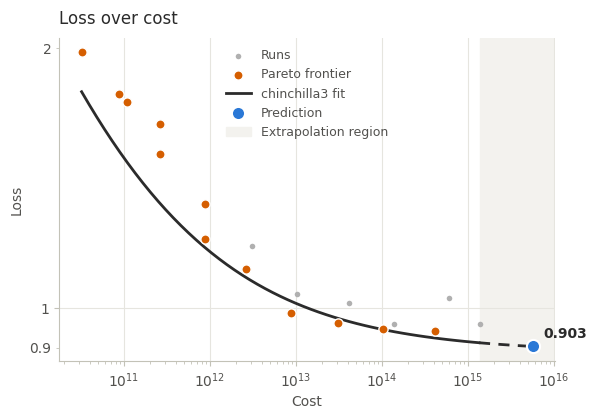

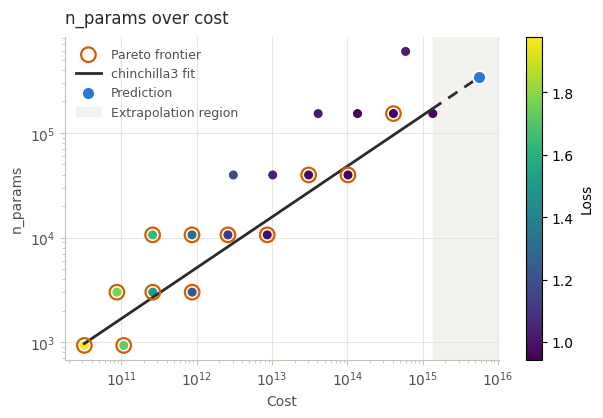

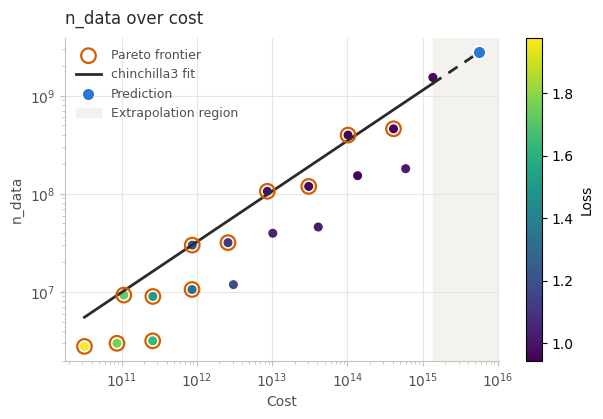

In [12]:
show(CHINCHILLA1 / "summary/pre_train/loss_over_cost.png",
     *[CHINCHILLA1 / f"summary/pre_train/parameters/{name}_over_cost.png"
       for name in ["n_params", "n_data"]])

The config is `None`: $L(N, D)$ fit doesn't model parameter space directly. Let's fallback to `power_law fit` to model all underlying HPs and predict their corresponding value in target regime.

## 2. The default scaling pipeline

By default, `acquire` uses random search: it samples configs of the
whole space, the hyperparameters included, each costing at most `max_cost_per_config`,
until the budget is spent. `predict` with its default `predictor="auto"` then fits
`power_law`, the predictor of random search, which also predicts every hyperparameter.

INFO:scalefm.api:Starting scalefm.acquire using root directory results/scaling_tutorial/default
INFO:scalefm.api:SearchSpace(elements={'effective_batch_size': HPOInteger(lower=16, upper=256, center=64, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=False), 'embedding_size': HPOInteger(lower=4, upper=256, center=32, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'lr': HPOFloat(lower=0.0001, upper=0.05, center=0.002236067977499791, log=True, log_base=None, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=False), 'num_layers': HPOInteger(lower=2, upper=32, center=8, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'total_cells': HPOInteger(lower=1048576, upper=34359738368, center=268435456, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True)}, categoricals={}

C=5.6e+15: loss 0.570, N*=1.66e+06, D*=5.61e+08
config: {'effective_batch_size': 32, 'embedding_size': 8, 'lr': 0.0008256688597612083, 'num_layers': 2, 'total_cells': 34359738368}


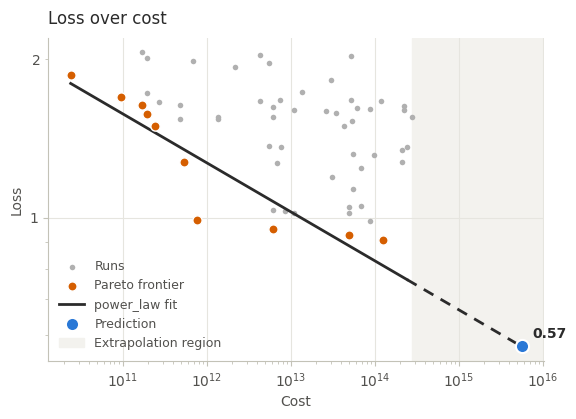

In [13]:
DEFAULT = RESULTS / "default"

tabpfn.set_seed(0)
scalefm.acquire(
    evaluate_pipeline=evaluate_pipeline,
    pipeline_space=TabPFNSpace(),
    root_directory=DEFAULT,
    cost_estimator=tabpfn.flops_estimator,
    max_cost_per_config=MAX_COST_PER_RUN,
    total_cost_to_spend=BUDGET,
    overwrite_root_directory=True,
)

predictions = scalefm.predict(DEFAULT, target_costs=TARGETS)
for target, prediction in zip(TARGETS, predictions):
    print(f"C={target:.1e}: loss {prediction.loss:.3f},"
          f" N*={prediction.n_params:.2e}, D*={prediction.n_data:.2e}")
    print("config:", prediction.config)
show(DEFAULT / "summary/pre_train/loss_over_cost.png")

### The individual hyperparameters

Every hyperparameter gets its own fit over the frontier runs, and a prediction at
each target:

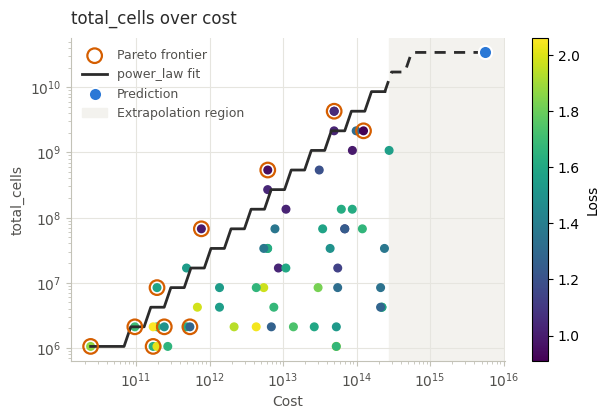

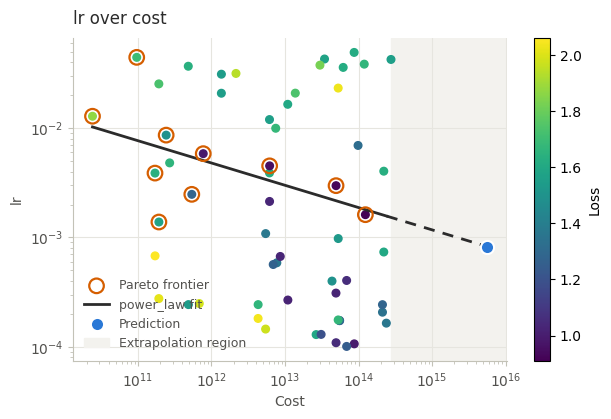

In [14]:
show(*[DEFAULT / f"summary/pre_train/parameters/{name}_over_cost.png"
       for name in ["total_cells", "lr",]],
     width=420)

The prediction at each target, loss, model size, data and config, is saved as a
table next to the plots, as CSV and as text:

In [15]:
print((DEFAULT / "summary/pre_train/predictions_over_cost.txt").read_text())

 target_cost   loss  n_params    n_data  effective_batch_size  embedding_size        lr  num_layers  total_cells
     5.6e+15 0.5698 1.665e+06 5.606e+08                    32               8 0.0008257           2  34359738368



## 3. Downstream performance

Every metric in `downstream_performances` gets the same scaling fit and prediction as
the loss, here the NLL on real datasets:

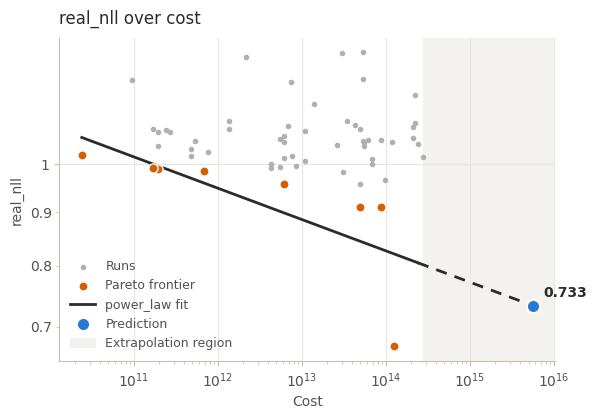

In [16]:
show(DEFAULT / "summary/downstream/real_nll/real_nll_over_cost.png")

## 4. Inference cost

When the runs report an `inference_cost`, the loss is also plotted over it, the best
loss a model of each inference cost reached:

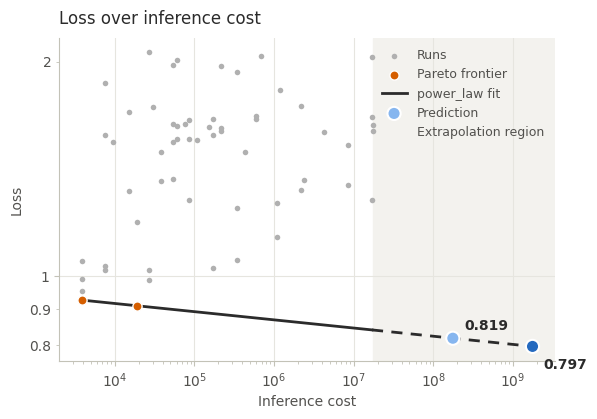

In [17]:
show(DEFAULT / "summary/pre_train/loss_over_inference_cost.png")

## 5. Parallel workers [for you to try!]

A real study runs many trainings at once. With ScaleFM you start the same
`acquire` call several times, as processes on the same machine, or as Slurm jobs on
different machines, all pointing at one `root_directory`: the workers share its FLOP
budget through the filesystem.

To give the runs a training time, `timed_evaluate_pipeline` waits as long as training
would take on a small simulated cluster. Below are three workers as processes of this
notebook (forked, as on Linux and Colab; on macOS or Windows run the `acquire` call
from a script in several terminals instead).

In [17]:
PARALLEL = RESULTS / "parallel"
shutil.rmtree(PARALLEL, ignore_errors=True)


def timed_evaluate_pipeline(**config) -> dict:
    """`evaluate_pipeline`, taking as long as training on the simulated cluster."""
    result = evaluate_pipeline(**config)
    time.sleep(result["cost"] / tabpfn.SIMULATED_FLOPS_PER_SECOND)
    return result


def run_worker():
    scalefm.acquire(
        evaluate_pipeline=timed_evaluate_pipeline,
        pipeline_space=TabPFNSpace(),
        root_directory=PARALLEL,
        cost_estimator=tabpfn.flops_estimator,
        max_cost_per_config=MAX_COST_PER_RUN,
        total_cost_to_spend=BUDGET,
    )


processes = [mp.Process(target=run_worker) for _ in range(3)]
for p in processes:
    p.start()
for p in processes:
    p.join()

INFO:scalefm.api:Starting scalefm.acquire using root directory results/scaling_tutorial/parallel
INFO:scalefm.api:SearchSpace(elements={'effective_batch_size': HPOInteger(lower=16, upper=256, center=64, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=False), 'embedding_size': HPOInteger(lower=4, upper=256, center=32, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'lr': HPOFloat(lower=0.0001, upper=0.05, center=0.002236067977499791, log=True, log_base=None, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=False), 'num_layers': HPOInteger(lower=2, upper=32, center=8, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'total_cells': HPOInteger(lower=1048576, upper=34359738368, center=268435456, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True)}, categoricals={

The three workers split the runs between them:

In [18]:
full, _ = scalefm.status(PARALLEL)
training_time = (full["cost"] / tabpfn.SIMULATED_FLOPS_PER_SECOND).sum()
wall_clock = full["time_end"].max() - full["time_sampled"].min()
print(f"{full['cost'].sum():.2e} FLOPs spent of {BUDGET:.2e}")
print(f"training time {training_time:.0f}s, wall clock {wall_clock:.0f}s")
full.groupby("evaluating_worker_id")["cost"].agg(runs="count", flops="sum")

3.16e+15 FLOPs spent of 2.80e+15
training time 158s, wall clock 55s


,runs,flops
evaluating_worker_id,,
worker_0,24,1066170356522907.125
worker_1,29,1030712336158337.0
worker_2,22,1060655358529401.75


## 6. Asynchronous sampling and multi-GPU jobs [for you to try!]

On a cluster you rarely keep a worker alive for the whole study. Instead you sample
configs, hand each one to a job sized for it, and collect the results as the jobs
finish:

* With **`is_async=True`** and no `evaluate_pipeline`, `acquire` only samples. Each
  config is written to `configs/config_<id>/config.yaml` and stays pending.
* The job reads the config, trains it, and reports its result into the study with
  **`scalefm.save_pipeline_results`**.

A job can also train its config on several GPUs with **PyTorch DDP**: `torchrun`
starts one process per GPU, all of them train, and only rank 0 reports, so a
multi-GPU run is still one trial.

In [19]:
ASYNC = (RESULTS / "async").resolve()
shutil.rmtree(ASYNC, ignore_errors=True)


def sample(n_configs):
    """Sample `n_configs` configs, without training them."""
    scalefm.acquire(
        pipeline_space=TabPFNSpace(),
        root_directory=ASYNC,
        is_async=True,
        cost_estimator=tabpfn.flops_estimator,
        max_cost_per_config=MAX_COST_PER_RUN,
        total_cost_to_spend=BUDGET,
        # Pending configs have no cost yet, so bound each round by its size
        worker_evaluations_to_spend=n_configs,
    )


def pending_trials():
    """The ids of the sampled configs that have no result yet."""
    return [d.name.removeprefix("config_") for d in sorted(ASYNC.glob("configs/config_*"))
            if not (d / "report.yaml").exists()]


sample(4)
print("pending:", pending_trials())

INFO:scalefm.api:Starting scalefm.acquire using root directory /home/alipourn/extrapolaw/tutorials/results/scaling_tutorial/async
INFO:scalefm.api:SearchSpace(elements={'effective_batch_size': HPOInteger(lower=16, upper=256, center=64, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=False), 'embedding_size': HPOInteger(lower=4, upper=256, center=32, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'lr': HPOFloat(lower=0.0001, upper=0.05, center=0.002236067977499791, log=True, log_base=None, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=False), 'num_layers': HPOInteger(lower=2, upper=32, center=8, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'total_cells': HPOInteger(lower=1048576, upper=34359738368, center=268435456, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compu

pending: ['0', '1', '2', '3']


The job script, which reads its config from `config.yaml`. Every rank runs it, rank 0
reports. It reports the cost itself, as the `cost_estimator` of `acquire` only fills
in the cost of results returned by an `evaluate_pipeline`:

In [20]:
JOB = '''
import sys, time
import torch
import torch.distributed as dist
import yaml

import scalefm
import tabpfn_scan_bench as tabpfn

root, trial_id = sys.argv[1], sys.argv[2]
dist.init_process_group("gloo")  # "nccl" on GPUs
rank, world_size = dist.get_rank(), dist.get_world_size()

with open(f"{root}/configs/config_{trial_id}/config.yaml") as f:
    config = yaml.safe_load(f)
# Train: each rank works on its share of the batch, then the gradients are averaged
seconds = tabpfn.flops_estimator(**config) / tabpfn.SIMULATED_FLOPS_PER_SECOND
time.sleep(seconds / world_size)
gradient = torch.full((4,), float(rank))
dist.all_reduce(gradient)

if rank == 0:
    run = tabpfn.build_config(**config)
    result = {
        "objective_to_minimize": tabpfn.get_benchmark().query(run)["predictions"]["mean"],
        "cost": tabpfn.flops_estimator(**config),
        "n_params": tabpfn.parameters_estimator(**config),
        "n_data": run.total_cells,
        "info_dict": {"world_size": world_size},
    }
    scalefm.save_pipeline_results(result, pipeline_id=trial_id, root_directory=root)
dist.destroy_process_group()
'''
job_script = ASYNC / "job.py"
job_script.write_text(JOB)


def submit(trial_id, gpus=2):
    """Stands in for `sbatch`: runs the job on this machine, in the background."""
    env = {**os.environ, "PYTHONPATH": str(Path(tabpfn.__file__).parent)}
    return subprocess.Popen(
        [sys.executable, "-m", "torch.distributed.run", "--standalone",
         f"--nproc_per_node={gpus}", str(job_script), str(ASYNC), trial_id],
        env=env, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
    )


def run_pending():
    """Submit a job for every pending config, and wait for their exit codes."""
    jobs = {trial_id: submit(trial_id) for trial_id in pending_trials()}
    return {trial_id: job.wait() for trial_id, job in jobs.items()}


print("round 1, exit codes:", run_pending())
sample(4)  # The next round, within the same budget
print("round 2, exit codes:", run_pending())

INFO:scalefm.api:Starting scalefm.acquire using root directory /home/alipourn/extrapolaw/tutorials/results/scaling_tutorial/async
INFO:scalefm.api:SearchSpace(elements={'effective_batch_size': HPOInteger(lower=16, upper=256, center=64, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=False), 'embedding_size': HPOInteger(lower=4, upper=256, center=32, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'lr': HPOFloat(lower=0.0001, upper=0.05, center=0.002236067977499791, log=True, log_base=None, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=False), 'num_layers': HPOInteger(lower=2, upper=32, center=8, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compute_scaling=True), 'total_cells': HPOInteger(lower=1048576, upper=34359738368, center=268435456, log=True, log_base=2, prior=None, prior_confidence='low', is_fidelity=False, is_compu

round 1, exit codes: {'0': 0, '1': 0, '2': 0, '3': 0}
round 2, exit codes: {'4': 0, '5': 0, '6': 0, '7': 0}


Every job reported from rank 0 of its two processes, into the same study:

In [21]:
full, _ = scalefm.status(ASYNC)
full[["config.embedding_size", "config.num_layers", "config.total_cells",
      "objective_to_minimize", "cost", "extra.world_size"]].sort_values("cost")

,config.embedding_size,config.num_layers,config.total_cells,objective_to_minimize,cost,extra.world_size
id,,,,,,
5,4,32,4194304,1.866,769604386734.470093,2
4,4,8,16777216,1.291,770313298607.60437,2
7,4,2,134217728,1.362,1546297892200.282471,2
6,16,8,8388608,2.03,2727180131463.145508,2
0,4,8,268435456,1.067,12325012777721.669922,2
2,8,8,536870912,0.955,61956622142864.671875,2
3,64,2,134217728,0.957,119884358548080.234375,2
1,32,16,134217728,1.587,275663373223789.5625,2


## Takeaways

1. **Define** the pipeline and space, **acquire** runs within a FLOP budget,
   **predict** at the target compute.
2. **Predict** loss, model size and data, and a full config (`power_law` or
   `gp_posterior`; not `chinchilla3`), for the loss and every downstream metric.
3. Check the scaling plots in `summary/`, over the training and the inference cost.
4. **Parallelization**: workers share one budget, async jobs report back, DDP works.